# 3-Factor Vasicek Term Structure Model: a guided walkthrough

This notebook builds the model step by step using the `vasicek3f` package in `src/`.
Each section maps to one module, so you can read the theory here and the
implementation there.

| Section | Module |
|---|---|
| 1. Data and why three factors | `data.py`, `diagnostics.py` |
| 2. Affine pricing under Q | `affine.py` |
| 3. P dynamics and exact discretisation | `discretize.py` |
| 4. State-space form and the Kalman filter | `kalman.py`, `model.py` |
| 5. Starting values and maximum likelihood | `estimation.py` |
| 6. Filtered/smoothed states and fit | `model.py`, `diagnostics.py` |
| 7. Term premium decomposition | `decomposition.py` |
| 8. Where to be careful | — |

By default it runs on **simulated data** (known true parameters, so we can check
recovery). Set `USE_GSW = True` and point to the Fed GSW file to run on Treasuries.

> Educational project, not a production term premium model.

In [1]:
import os, sys, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))

from vasicek3f import (VasicekParams, q_loadings, p_loadings, eh_loadings, loglik,
                       filter_and_smooth, estimate, starting_values,
                       term_premium_decomposition, default_true_params, simulate_panel)
from vasicek3f.discretize import discretize_ou, unconditional_moments
from vasicek3f.diagnostics import pca_explained, pricing_errors, factor_correlations
from vasicek3f import data as D
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.grid": True, "grid.alpha": .3})

USE_GSW  = False
GSW_PATH = "../data/feds200628.csv"
ACM_PATH = "../data/ACMTermPremium.xls"
KW_PATH  = "../data/THREEFYTP10.csv"
TAU = np.arange(1.0, 11.0)      # maturities in years
DT  = 1 / 12                    # monthly sampling

## 1. Data and why three factors

Yields are continuously compounded zero-coupon yields in decimals. GSW (Gürkaynak-Sack-Wright)
publishes fitted zero yields `SVENYxx`; we take month-end values. In simulation we also keep
the true states and the true term premium.

(480, 10) 1986-01-31 → 2025-12-31


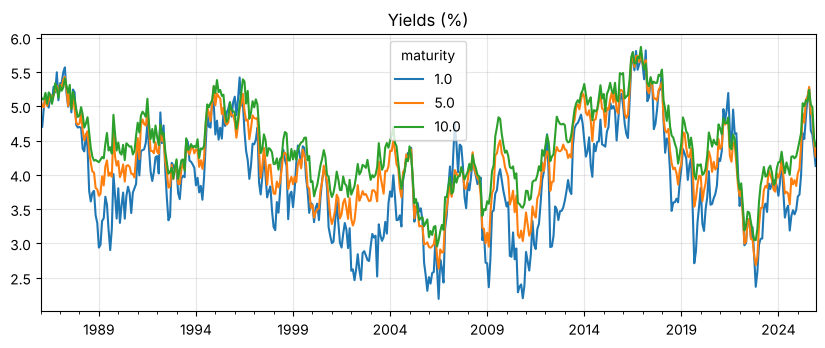

,variance share
PC1,96.29%
PC2,3.14%
PC3,0.30%
PC4,0.04%
PC5,0.04%


In [2]:
if USE_GSW:
    yields = D.load_gsw(GSW_PATH, TAU, start="1990-01").dropna()
    true_p, truth = None, None
    bench = {}
    if os.path.exists(ACM_PATH): bench["ACM"] = D.load_acm(ACM_PATH, 10)
    if os.path.exists(KW_PATH):  bench["KW"]  = D.load_kw(KW_PATH)
else:
    true_p = default_true_params(len(TAU))
    truth = simulate_panel(true_p, TAU, n_periods=480, dt=DT, seed=42)
    yields = truth["yields"]
    bench = {"True TP": truth["term_premium"][10.0]}

print(yields.shape, yields.index.min().date(), "→", yields.index.max().date())
(yields[[1.0, 5.0, 10.0]] * 100).plot(title="Yields (%)"); plt.show()
pca_explained(yields).to_frame("variance share").style.format("{:.2%}")

Three principal components explain essentially all of the cross-sectional variation
(level, slope, curvature). That is the empirical case for three latent factors.

## 2. Affine pricing under the pricing measure Q

Canonical (Joslin-Singleton-Zhu style) normalisation:

$$dx_t = -K^Q x_t\,dt + \Sigma\,dW^Q_t,\quad K^Q=\mathrm{diag}(\kappa_1<\kappa_2<\kappa_3),\quad r_t=\delta_0+\iota'x_t$$

Bond prices are $P_t(\tau)=\exp(A(\tau)+B(\tau)'x_t)$ and yields are affine,
$y_t(\tau)=a(\tau)+b(\tau)'x_t$, with closed forms

$$b_i(\tau)=\frac{1-e^{-\kappa_i\tau}}{\kappa_i\tau},\qquad
a(\tau)=\delta_0-\frac{1}{2\tau}\sum_{ij}(\Sigma\Sigma')_{ij}\int_0^\tau\phi_i(s)\phi_j(s)\,ds,\quad \phi_i(s)=\frac{1-e^{-\kappa_i s}}{\kappa_i}.$$

The second term in $a(\tau)$ is the convexity adjustment: it pulls long yields down.

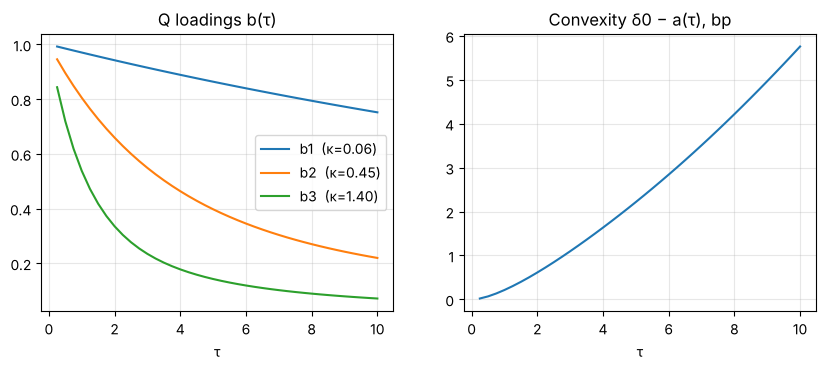

In [3]:
p0 = true_p if true_p is not None else starting_values(yields.values, TAU, DT)
grid = np.linspace(0.25, 10, 40)
a, b = q_loadings(p0, grid)
fig, ax = plt.subplots(1, 2)
for i in range(3): ax[0].plot(grid, b[:, i], label=f"b{i+1}  (κ={p0.kappa_Q[i]:.2f})")
ax[0].set_title("Q loadings b(τ)"); ax[0].legend(); ax[0].set_xlabel("τ")
ax[1].plot(grid, (p0.delta0 - a) * 1e4); ax[1].set_title("Convexity δ0 − a(τ), bp"); ax[1].set_xlabel("τ")
plt.show()

A slow factor (small κ) has a flat loading near 1: it shifts the whole curve (level).
Faster factors decay with maturity: slope- and curvature-like.

## 3. Physical dynamics and exact discretisation

Under the physical measure $P$, $dx_t = K^P(\theta^P-x_t)dt+\Sigma\,dW^P_t$ with a full $K^P$.
The change of measure is the essentially-affine market price of risk

$$\Sigma\lambda_t = K^P\theta^P + (K^Q-K^P)\,x_t .$$

Sampled monthly, the OU process is exactly a VAR(1): $x_{t+\Delta}=c+Fx_t+\eta_t$ with
$F=e^{-K^P\Delta}$, $c=(I-F)\theta^P$ and $Q=\int_0^\Delta e^{-K^Ps}\Sigma\Sigma'e^{-K^{P\prime}s}ds$,
computed with Van Loan's block matrix exponential.

In [4]:
c, F, Qd = discretize_ou(p0.K_P, p0.theta_P, p0.Sigma, DT)
print("eigenvalues of F (monthly persistence):", np.round(np.linalg.eigvals(F).real, 4))
print("P half-lives (years):", np.round(p0.factor_half_lives()["P"], 2))
print("market price of risk λ1:\n", np.round(p0.market_price_of_risk()["lambda1"], 2))

eigenvalues of F (monthly persistence): [0.8825 0.9433 0.9835]
P half-lives (years): [0.46 0.99 3.47]
market price of risk λ1:
 [[-17.5    0.     0.  ]
 [-19.33 -16.67   0.  ]
 [-10.06 -33.33  -7.14]]


## 4. State-space form and the Kalman filter

* **Measurement** (from Q pricing): $y_t = a + Hx_t + e_t,\ e_t\sim N(0,\mathrm{diag}(\sigma_e^2))$
* **Transition** (from P dynamics): $x_t = c + F x_{t-1} + \eta_t,\ \eta_t\sim N(0,Q)$

The cross-section pins down the Q parameters; the time-series behaviour of the states pins
down the P parameters. The Kalman filter turns this into one exact Gaussian likelihood
through the prediction-error decomposition
$\log L=-\tfrac12\sum_t[n\log 2\pi+\log|S_t|+v_t'S_t^{-1}v_t]$.

In [5]:
t0 = time.time(); ll0 = loglik(p0, yields.values, TAU, DT)
print(f"log-likelihood at {'true' if true_p is not None else 'starting'} parameters: {ll0:,.2f}"
      f"  ({(time.time()-t0)*1000:.1f} ms per evaluation)")

log-likelihood at true parameters: 28,437.28  (3.8 ms per evaluation)


The fast evaluation comes from two exact shortcuts in `kalman.py`: the **collapsed filter**
(Jungbacker & Koopman 2015) runs the filter on the 3-dimensional GLS projection of the 10
yields, and once the covariance converges the filter switches to its **steady state**.
Unit tests check both against the plain filter and a brute-force multivariate normal.

## 5. Starting values and maximum likelihood

Stage 1: for trial $\kappa^Q$, states are per-date OLS regressions of yields on $b(\tau)$ and
$\delta_0$ has a closed-form pooled solution. Stage 2: a VAR(1) on those states gives $K^P$,
$\theta^P$ and $\Sigma$. Stage 3: joint MLE of all 32 parameters.

In [6]:
res = estimate(yields.values, TAU, DT, compute_se=True, verbose=True)
p_hat = res.params
print(f"\nlog-likelihood {res.loglik:,.2f} in {res.elapsed_sec:.0f}s")
se = res.std_errors.copy()
if true_p is not None:
    from vasicek3f.params import ParamTransform
    se.insert(0, "true", ParamTransform(len(TAU)).natural_vector(true_p))
se.head(22).style.format("{:.4f}")

Stage 1-2: cross-sectional fit + VAR starting values


  [start 1] kappa_Q=[0.0538 0.4224 1.5141] delta0=0.0672 cross-section RMSE=3.36bp


  [start 2] kappa_Q=[0.0537 0.4238 1.5084] delta0=0.0619 cross-section RMSE=3.36bp
Stage 3: MLE run 1/1  start loglik=28,360.2


         -> loglik=28,455.51  (CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH)
Computing numerical Hessian for standard errors ...



log-likelihood 28,455.51 in 23s


,true,estimate,std_error,t_stat
kappaQ_1,0.0600,0.0531,0.0060,8.8665
kappaQ_2,0.4500,0.4294,0.0370,11.6069
kappaQ_3,1.4000,1.5393,0.1678,9.1748
delta0,0.0600,0.0620,0.0018,34.2137
Sigma_11,0.0080,0.0082,0.0005,15.1963
Sigma_21,-0.0080,-0.0072,0.0012,-5.8635
Sigma_22,0.0150,0.0145,0.0013,10.7272
Sigma_31,0.0030,0.0022,0.0012,1.7488
Sigma_32,-0.0100,-0.0081,0.0021,-3.8722
Sigma_33,0.0140,0.0130,0.0009,13.7878


Compare the t-statistics: κQ, δ0 and Σ are sharply estimated; most elements of $K^P$ are not.
This is the central identification lesson of affine term structure models: **the
cross-section of yields is very informative about Q, a few decades of monthly data are not
very informative about P**, and the term premium depends on P.

## 6. Smoothed states and fit

,mean_bp,mae_bp,rmse_bp,max_abs_bp,ar1
maturity,,,,,
1.000000,-0.06,2.02,2.51,9.16,-0.31
2.000000,0.17,2.26,2.80,7.70,-0.07
3.000000,-0.25,2.82,3.61,11.36,-0.07
4.000000,-0.08,3.14,3.97,12.97,-0.00
5.000000,0.11,2.99,3.83,14.92,-0.03
6.000000,0.09,3.06,3.76,10.92,-0.04
7.000000,-0.02,3.13,3.91,13.42,-0.01
8.000000,-0.03,2.90,3.58,9.57,0.02
9.000000,0.00,2.89,3.66,11.54,-0.07


,level,slope,curvature
x1,0.87,0.02,0.12
x2,0.01,-0.55,-0.05
x3,0.05,-0.20,-0.67


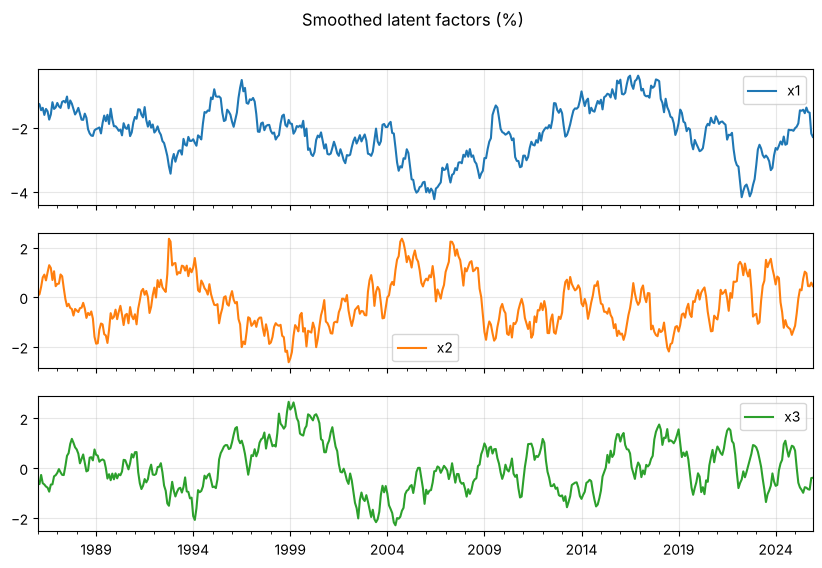

In [7]:
fs = filter_and_smooth(p_hat, yields.values, TAU, DT)
X = pd.DataFrame(fs["x_smoothed"], index=yields.index, columns=["x1", "x2", "x3"])
fitted = pd.DataFrame(fs["fitted_smoothed"], index=yields.index, columns=yields.columns)
display(pricing_errors(yields, fitted).style.format("{:.2f}"))
display(factor_correlations(X, yields).style.format("{:.2f}"))
(X * 100).plot(subplots=True, figsize=(10, 6), title="Smoothed latent factors (%)"); plt.show()

## 7. Term premium decomposition

$$\underbrace{TP_t(\tau)}_{\text{term premium}} = \underbrace{a^Q(\tau)+b^Q(\tau)'x_t}_{\text{pricing-measure fitted yield}} - \underbrace{a^P(\tau)+b^P(\tau)'x_t}_{\text{physical-measure affine yield}}$$

$a^P, b^P$ solve the same pricing ODEs with the physical drift, i.e. the yield the model would
produce with a zero market price of risk. This is **not** a strict Expectations-Hypothesis
estimate: it equals the average expected short rate minus a P-convexity term (also computed).

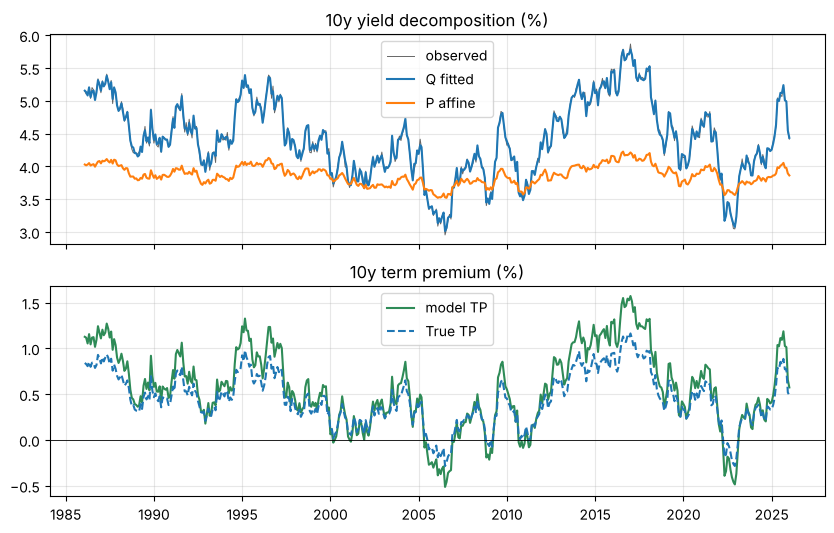

mean P-convexity at 10y (EH − P-affine): 0.9 bp
vs True TP: corr 0.999, mean diff +10.8 bp


In [8]:
dec = term_premium_decomposition(p_hat, X.values, TAU, yields.index)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(yields.index, yields[10.0]*100, color="k", lw=.7, alpha=.6, label="observed")
ax[0].plot(dec["fitted_Q"].index, dec["fitted_Q"][10.0]*100, label="Q fitted")
ax[0].plot(dec["affine_P"].index, dec["affine_P"][10.0]*100, label="P affine")
ax[0].legend(); ax[0].set_title("10y yield decomposition (%)")
ax[1].plot(dec["term_premium"].index, dec["term_premium"][10.0]*100, color="seagreen", label="model TP")
for k, s in bench.items():
    s = s.loc[yields.index.min():yields.index.max()]
    ax[1].plot(s.index, s*100, ls="--", label=k)
ax[1].axhline(0, color="k", lw=.6); ax[1].legend(); ax[1].set_title("10y term premium (%)")
plt.show()
conv = dec["convexity_P"][10.0]*1e4
print(f"mean P-convexity at 10y (EH − P-affine): {conv.mean():.1f} bp")
for k, s in bench.items():
    j = pd.concat([dec['term_premium'][10.0], s], axis=1).dropna()
    print(f"vs {k}: corr {j.corr().iloc[0,1]:.3f}, mean diff {(j.iloc[:,0]-j.iloc[:,1]).mean()*1e4:+.1f} bp")

## 8. Where the model is strong, and where to be careful

**Strong**
* Exact, closed-form pricing; internally consistent P/Q structure; no-arbitrage by construction.
* Fits the cross-section to a few basis points with three factors.
* Exact likelihood (exact discretisation, exact Kalman filter), testable end to end by simulation.

**Be careful**
* **Weak P identification.** $K^P$ is estimated from the time series of highly persistent
  states; small-sample bias typically makes estimated mean reversion too fast, which pushes
  expected rates back to their mean too quickly and attributes more of long yields to the term
  premium. In the simulation above, the TP *dynamics* track the truth closely while the *level*
  is off by a few to tens of basis points.
* **Gaussian model**: yields can go negative, volatility is constant, and the zero lower bound
  period is not modelled well.
* **No survey or macro information**: Kim-Wright uses survey forecasts to discipline P; ACM uses
  a different estimation approach. Differences from those benchmarks are expected.
* **The P-affine yield is a model benchmark**, not an observed expectation. It differs from a
  strict EH component by P-convexity.

Next: open the dashboard (`streamlit run streamlit_app.py`) to explore the same results
interactively and to run sensitivity analysis on the parameters.